# Data Visualization — Quiz (Lectures 1–7)

**Time:** 90 minutes 
**Tools:** Plotly only (`plotly.express` first, then `update_traces` / `update_layout` / `update_xaxes` / `update_yaxes`)

**Your task:** answer each analytical question with **one polished, explanatory visualization**. For every question **you decide which chart type fits best** — and justify the choice in one or two sentences.

**Every figure must have:**
1. An **insight title** that states the finding, not just the variables
2. `template='plotly_white'` and a decluttered layout (no unnecessary gridlines, legends or axis titles)
3. A **CVD-safe palette** — no red/green; grey for context + one accent colour where it helps
4. Colour that **encodes meaning**, not decoration
5. Direct labels or annotations where they help the reader

**Chart types covered in the course** — choose from these:
line chart · sorted bar chart · stacked / 100% stacked bar chart · scatter plot · bubble chart · histogram · box plot · violin plot · choropleth map · treemap

> 💡 Each question has one chart type that fits it best, and the questions together cover most of the list above. If two of your answers use the same chart type, check the question again.


**Submit:** this notebook pushed to your personal repo as `quiz/dataviz_quiz.ipynb`

## The dataset — World Population 1970–2022

**Source:** [World Population Dataset](https://www.kaggle.com/datasets/iamsouravbanerjee/world-population-dataset) on Kaggle, compiled from Worldometer (UN World Population Prospects estimates). **234 rows × 16 columns — one row per country or territory, no missing values.**

| Column | Type | Description |
|---|---|---|
| `Country`, `Capital` | categorical | Country / territory and its capital |
| `Continent` | categorical | Africa, Asia, Europe, North America, Oceania, South America |
| `CCA3` | spatial | ISO-3 country code — use with `locationmode='ISO-3'` |
| `1970 Population` … `2022 Population` | temporal | Population in 1970, 1980, 1990, 2000, 2010, 2015, 2020, 2022 |
| `Area` | numerical | Land area in km² |
| `Density` | numerical | People per km² (2022) |
| `World share (%)` | numerical | Share of world population in 2022 |
| `Rank` | numerical | Rank by 2022 population |

**The next setup cell also gives you `df_long` — the same data in **tidy (long) format** with one row per country per year. Use `df` for one-year questions and `df_long` for questions about change over time**

In [2]:
import pandas as pd
import plotly.express as px
import numpy as np

df = pd.read_csv('world_population.csv')

# Shorter column names
df = df.rename(columns={'Country/Territory': 'Country', 'Area (km²)': 'Area',
                        'Density (per km²)': 'Density', 'World Population Percentage': 'World share (%)'})

# Tidy (long) version: one row per country per year
year_cols = [c for c in df.columns if c.endswith('Population')]
df_long = df.melt(id_vars=['CCA3', 'Country', 'Continent'], value_vars=year_cols,
                  var_name='Year', value_name='Population')

df_long['Year'] = df_long['Year'].str[:4].astype(int)     # '2022 Population' → 2022

print(df.shape, df_long.shape)
df.head()

(234, 16) (1872, 5)


,Rank,CCA3,Country,Capital,Continent,2022 Population,2020 Population,2015 Population,2010 Population,2000 Population,1990 Population,1980 Population,1970 Population,Area,Density,World share (%)
0,36,AFG,Afghanistan,Kabul,Asia,41128771,38972230,33753499,28189672,19542982,10694796,12486631,10752971,652230,63.0587,0.52
1,138,ALB,Albania,Tirana,Europe,2842321,2866849,2882481,2913399,3182021,3295066,2941651,2324731,28748,98.8702,0.04
2,34,DZA,Algeria,Algiers,Africa,44903225,43451666,39543154,35856344,30774621,25518074,18739378,13795915,2381741,18.8531,0.56
3,213,ASM,American Samoa,Pago Pago,Oceania,44273,46189,51368,54849,58230,47818,32886,27075,199,222.4774,0.00
4,203,AND,Andorra,Andorra la Vella,Europe,79824,77700,71746,71519,66097,53569,35611,19860,468,170.5641,0.00


---
## Q1 — Which continent is growing fastest?

How has the population of each continent **grown since 1970, relative to its 1970 size** — and which continent is growing fastest?


**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

linear graph. Because here we need to show how population changed throught time and compare growth between continents

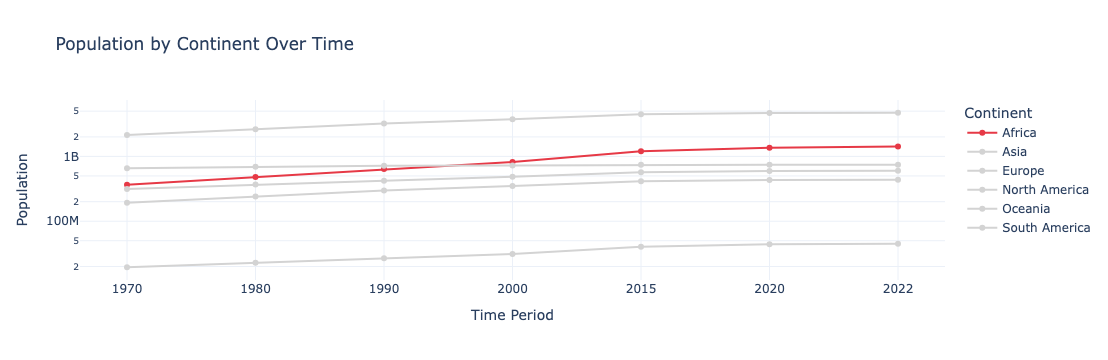

In [37]:
# Q1
df_1 = df.groupby(["Continent"], as_index=False).sum(numeric_only=True)

df_long = df_1.melt(
    id_vars=["Continent"],
    value_vars=["1970 Population", "1980 Population", "1990 Population", "2000 Population", "2015 Population", "2020 Population", "2022 Population"],
    var_name="year",
    value_name="population",
)
df_long["year"] = df_long["year"].str.replace(" Population", "", case=False)


df_long["absolute_growth"] = df["2022 Population"] - df["1990 Population"]
df_long["pct_growth"] = (
    (df["2022 Population"] - df["1990 Population"])
    / df["1990 Population"]
) * 100
fastest_continent = df_long.loc[df_long["pct_growth"].idxmax()]

target = "Africa"

color_map = {
    c: ("#E63946" if c == target else "lightgrey")
    for c in df_long["Continent"].unique()
}

fig = px.line(
    df_long,
    x="year",
    y="population",
    color="Continent",
    color_discrete_map=color_map,
    markers=True,
    log_y=True,
    title="Population by Continent Over Time",
    labels={
        "year": "Time Period",
        "population": "Population",
        "continent": "Continent",
    },
    template='plotly_white'
)

df_long.head()
fig.show()


---
## Q2 — Which countries added the most people?

Which **15 countries added the most people** between 1970 and 2022 — and how many of them are in **Africa**?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*

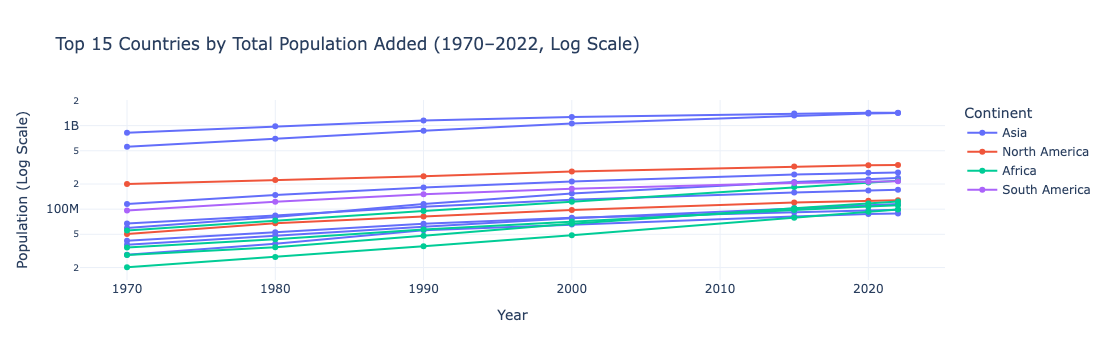

In [67]:
# Q2
import pandas as pd
import plotly.express as px

# 1. Reshape wide df into long format (df_2) with lowercase "year"
df_2 = df.melt(
    id_vars=["Country", "Continent"],
    value_vars=[
        "1970 Population",
        "1980 Population",
        "1990 Population",
        "2000 Population",
        "2015 Population",
        "2020 Population",
        "2022 Population",
    ],
    var_name="year",
    value_name="population",
)

df_2["year"] = (
    df_2["year"].str.replace(" Population", "", case=False).astype(int)
)

df_sorted = df_2.sort_values(by=["Country", "year"])

growth_df = df_sorted.groupby(["Country", "Continent"], as_index=False).agg(
    start_pop=("population", "first"),
    end_pop=("population", "last"),
)
growth_df["people_added"] = growth_df["end_pop"] - growth_df["start_pop"]

top_15_df = growth_df.nlargest(15, "people_added")
top_15_countries = top_15_df["Country"].tolist()

df_top15_long = df_2[df_2["Country"].isin(top_15_countries)].sort_values("year")

fig = px.line(
    df_top15_long,
    x="year",
    y="population",
    color="Continent",
    line_group="Country",
    hover_name="Country",
    markers=True,
    log_y=True,
    title="Top 15 Countries by Total Population Added (1970–2022, Log Scale)",
    labels={"year": "Year", "population": "Population (Log Scale)"},
    template='plotly_white'
)

fig.show()


---
## Q3 — Do bigger countries have more people?

Is there a relationship between a country's **land area** and its **2022 population** — does it differ by **continent**, and which countries clearly break the pattern?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*

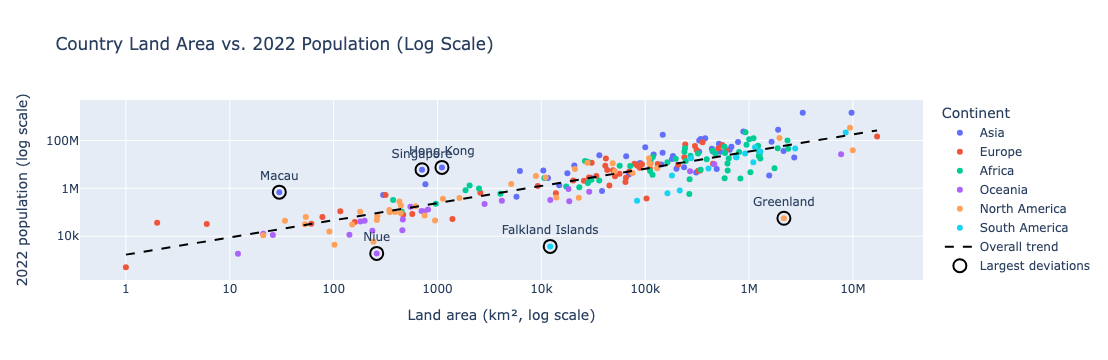

In [71]:
# Q3
# YOUR CODE HERE

df_q3 = df.dropna(subset=["Country", "Continent", "Area", "2022 Population"]).copy()
df_q3 = df_q3[(df_q3["Area"] > 0) & (df_q3["2022 Population"] > 0)]

df_q3["log_area"] = np.log10(df_q3["Area"])
df_q3["log_population"] = np.log10(df_q3["2022 Population"])

# Find countries furthest above and below the overall log-log trend.
slope, intercept = np.polyfit(df_q3["log_area"], df_q3["log_population"], 1)
df_q3["trend_residual"] = df_q3["log_population"] - (
    intercept + slope * df_q3["log_area"]
)
outliers = pd.concat([
    df_q3.nlargest(3, "trend_residual"),
    df_q3.nsmallest(3, "trend_residual"),
]).drop_duplicates(subset="Country")

fig = px.scatter(
    df_q3,
    x="Area",
    y="2022 Population",
    color="Continent",
    hover_name="Country",
    hover_data={
        "Area": ":,",
        "2022 Population": ":,",
        "Density": ":.1f",
        "log_area": False,
        "log_population": False,
        "trend_residual": False,
    },
    log_x=True,
    log_y=True,
    title="Country Land Area vs. 2022 Population (Log Scale)",
    labels={
        "Area": "Land area (km², log scale)",
        "2022 Population": "2022 population (log scale)",
        "Continent": "Continent",
    },
)

# Add a global trend line, calculated in log space.
trend_area = np.logspace(df_q3["log_area"].min(), df_q3["log_area"].max(), 100)
trend_population = 10 ** (intercept + slope * np.log10(trend_area))
fig.add_scatter(
    x=trend_area,
    y=trend_population,
    mode="lines",
    line={"color": "black", "dash": "dash"},
    name="Overall trend",
)

# Outline and label countries with the largest deviations from the trend.
fig.add_scatter(
    x=outliers["Area"],
    y=outliers["2022 Population"],
    text=outliers["Country"],
    mode="markers+text",
    textposition="top center",
    marker={"symbol": "circle-open", "size": 13, "color": "black", "line": {"width": 2}},
    name="Largest deviations",
    hovertext=outliers["Country"],
    hovertemplate="%{hovertext}<extra></extra>",
)

fig.show()

---
## Q4 — How crowded are the continents?

How does **population density vary within and across continents**? Show the spread, not just the average.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*

In [ ]:
# Q4
df_q4 = df.dropna(subset=["Continent", "Area", "2022 Population"]).copy()
df_q4 = df_q4[df_q4["Area"] > 0]

# Sum population and land area by continent, then calculate weighted density.
continent_density = df_q4.groupby("Continent", as_index=False).agg(
    population_2022=("2022 Population", "sum"),
    land_area=("Area", "sum"),
)
continent_density["Density"] = (
    continent_density["population_2022"] / continent_density["land_area"]
)

continent_order = ["Africa", "Asia", "Europe", "North America", "Oceania", "South America"]
continent_density["Continent"] = pd.Categorical(
    continent_density["Continent"], categories=continent_order, ordered=True
)
continent_density = continent_density.sort_values("Continent")

fig = px.bar(
    continent_density,
    x="Continent",
    y="Density",
    color="Continent",
    hover_data={
        "Density": ":.1f",
        "population_2022": ":,",
        "land_area": ":,",
    },
    title="Population Density by Continent (2022)",
    labels={
        "Continent": "Continent",
        "Density": "Population density (people per km²)",
        "population_2022": "2022 population",
        "land_area": "Land area (km²)",
    },
)

fig.update_layout(showlegend=False)
fig.show()

---
## Q5 — Where did populations grow — and where did they shrink?

Which 7 countries' populations **grew the most and shrank the most between 2020 and 2022** (percentage change)?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*

In [ ]:
# Q5
df_q5 = df.dropna(
    subset=["Country", "Continent", "2020 Population", "2022 Population"]
).copy()
df_q5 = df_q5[df_q5["2020 Population"] > 0].copy()
df_q5["Change (%)"] = (
    (df_q5["2022 Population"] - df_q5["2020 Population"])
    / df_q5["2020 Population"] * 100
)

top_growing = df_q5.nlargest(7, "Change (%)").assign(Change="Growing")
top_shrinking = df_q5.nsmallest(7, "Change (%)").assign(Change="Shrinking")
df_q5_selected = pd.concat([top_growing, top_shrinking], ignore_index=True)

# Sort positive changes first and the steepest declines last.
df_q5_selected = df_q5_selected.sort_values("Change (%)", ascending=False)
country_order = df_q5_selected["Country"].tolist()

fig = px.bar(
    df_q5_selected,
    x="Country",
    y="Change (%)",
    color="Change",
    category_orders={"Country": country_order, "Change": ["Growing", "Shrinking"]},
    hover_data={
        "Continent": True,
        "2020 Population": ":,",
        "2022 Population": ":,",
    },
    color_discrete_map={"Growing": "hotpink", "Shrinking": "blue"},
    title="Top 7 Population Increases and Declines (2020–2022)",
    labels={
        "Country": "Country",
        "Change (%)": "Population change (2020–2022, %)",
        "Change": "Population change",
    },
)

fig.add_hline(y=0, line_color="black", line_width=1)
fig.update_xaxes(tickangle=-45)
fig.show()

---
## Q6 — Which countries are most densely populated?

How does **2022 population density** vary around the world? Color the least dense countries blue and the most dense countries red.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*

In [ ]:
# Q6
df_q6 = df.dropna(subset=["CCA3", "Country", "Continent", "Density"]).copy()
df_q6["Log density"] = np.log10(df_q6["Density"] + 1)

fig = px.choropleth(
    df_q6,
    locations="CCA3",
    locationmode="ISO-3",
    color="Log density",
    color_continuous_scale=[[0, "blue"], [0.5, "white"], [1, "red"]],
    hover_name="Country",
    hover_data={
        "Continent": True,
        "Density": ":.1f",
        "Log density": False,
        "2022 Population": ":,",
    },
    title="2022 Population Density Around the World",
    labels={
        "Log density": "log10(population density + 1)",
        "Density": "Population density (people per km²)",
        "CCA3": "Country code",
    },
)

fig.update_geos(showcoastlines=True, showcountries=True)
fig.show()

---
## Q7 — Whose share of the world is rising?

How have the shares of world population held by **Africa, Asia and Europe** changed from 1970 to 2022? Group the other three continents as `'Rest of the world'`.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*

In [5]:
# Q7
df_q7 = df[["Continent", "1970 Population", "2022 Population"]].melt(
    id_vars="Continent",
    value_vars=["1970 Population", "2022 Population"],
    var_name="Year",
    value_name="Population",
)
df_q7["Year"] = df_q7["Year"].str[:4].astype(int)
df_q7["Continent group"] = np.where(
    df_q7["Continent"].isin(["Africa", "Asia", "Europe"]),
    df_q7["Continent"],
    "Rest of the world",
)

continent_shares = df_q7.groupby(
    ["Year", "Continent group"], as_index=False, observed=True
).agg(Population=("Population", "sum"))
continent_shares["Share (%)"] = (
    continent_shares["Population"]
    / continent_shares.groupby("Year")["Population"].transform("sum")
    * 100
)

continent_order = ["Africa", "Asia", "Europe", "Rest of the world"]
fig = px.bar(
    continent_shares,
    x="Year",
    y="Share (%)",
    color="Continent group",
    text="Share (%)",
    barmode="stack",
    category_orders={
        "Year": [1970, 2022],
        "Continent group": continent_order,
    },
    hover_data={"Population": ":,"},
    title="Share of World Population by Continent: 1970 vs 2022",
    labels={
        "Year": "Year",
        "Share (%)": "Share of world population (%)",
        "Continent group": "Continent",
        "Population": "Population",
    },
)

fig.update_traces(texttemplate="%{y:.1f}%", textposition="inside")
fig.update_yaxes(range=[0, 100], ticksuffix="%")
fig.show()